In [55]:
url = 'http://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data'

In [56]:
column_names = ['MPG', 'Cylinders', 'Displacement' , 'Horsepower','Weight' ,'Acceleration' , 'Model Year','Origin']



In [57]:
import pandas as pd
df = pd.read_csv(url  ,sep= " ", comment='\t',  skipinitialspace=True , names=column_names)
df.head()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
0,18.0,8,307.0,130.0,3504.0,12.0,70,1
1,15.0,8,350.0,165.0,3693.0,11.5,70,1
2,18.0,8,318.0,150.0,3436.0,11.0,70,1
3,16.0,8,304.0,150.0,3433.0,12.0,70,1
4,17.0,8,302.0,140.0,3449.0,10.5,70,1


In [58]:
print(df.info())
print("-"*50)
print('length of the Datafarme ##',len(df))
print("-"*50)
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   MPG           398 non-null    float64
 1   Cylinders     398 non-null    int64  
 2   Displacement  398 non-null    float64
 3   Horsepower    398 non-null    object 
 4   Weight        398 non-null    float64
 5   Acceleration  398 non-null    float64
 6   Model Year    398 non-null    int64  
 7   Origin        398 non-null    int64  
dtypes: float64(4), int64(3), object(1)
memory usage: 25.0+ KB
None
--------------------------------------------------
length of the Datafarme ## 398
--------------------------------------------------
MPG             0
Cylinders       0
Displacement    0
Horsepower      0
Weight          0
Acceleration    0
Model Year      0
Origin          0
dtype: int64


In [59]:
from numpy import column_stack
col = ['object' ,'float64']
columns_ = df.select_dtypes(include=col)
columns_
for i in columns_.columns:
    df[i] = pd.to_numeric(df[i] , errors='coerce')
    df[i] = df[i].astype('float32')
print(df.dtypes)
print("-"*70)
df.reset_index(drop=True)
print(df.head(5))

MPG             float32
Cylinders         int64
Displacement    float32
Horsepower      float32
Weight          float32
Acceleration    float32
Model Year        int64
Origin            int64
dtype: object
----------------------------------------------------------------------
    MPG  Cylinders  Displacement  Horsepower  Weight  Acceleration  \
0  18.0          8         307.0       130.0  3504.0          12.0   
1  15.0          8         350.0       165.0  3693.0          11.5   
2  18.0          8         318.0       150.0  3436.0          11.0   
3  16.0          8         304.0       150.0  3433.0          12.0   
4  17.0          8         302.0       140.0  3449.0          10.5   

   Model Year  Origin  
0          70       1  
1          70       1  
2          70       1  
3          70       1  
4          70       1  


In [60]:
import sklearn
import sklearn.model_selection
from sklearn.model_selection import train_test_split

df_train , df_test = train_test_split(df, train_size = 0.8 , random_state=1 )


train_stats = df_train.describe().transpose()
print(train_stats)

              count         mean         std     min      25%     50%  \
MPG           318.0    23.583961    7.890751     9.0    17.50    23.0   
Cylinders     318.0     5.418239    1.682508     3.0     4.00     4.0   
Displacement  318.0   191.128937  102.212387    70.0   101.75   146.0   
Horsepower    312.0   103.317307   37.839809    46.0    75.00    92.0   
Weight        318.0  2952.047119  836.500671  1613.0  2220.75  2801.0   
Acceleration  318.0    15.717610    2.751966     8.5    14.00    15.5   
Model Year    318.0    75.921384    3.683467    70.0    73.00    76.0   
Origin        318.0     1.588050    0.808150     1.0     1.00     1.0   

                      75%          max  
MPG             29.799999    46.599998  
Cylinders        6.000000     8.000000  
Displacement   258.000000   455.000000  
Horsepower     122.750000   230.000000  
Weight        3533.750000  5140.000000  
Acceleration    17.400000    24.799999  
Model Year      79.000000    82.000000  
Origin        

In [61]:
numeric_cols_name = ['Cylinders',
                     'Displacement', 'Horsepower',
                     'Weight', 'Acceleration']

df_train_norm , df_test_norm = df_train.copy(), df_test.copy()


# Normalizing the Data Z_score
for c in numeric_cols_name:
    mean = train_stats.loc[c,'mean']
    std = train_stats.loc[c, 'std']
    df_train_norm.loc[:,c] = (df_train_norm.loc[:, c] - mean)/std
    df_test_norm.loc[:,c] = (df_test_norm.loc[:,c]-mean)/std

df_train_norm.tail()

/tmp/ipykernel_500/1591829025.py:12: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 1.53447167  1.53447167 -0.84293145 -0.84293145 -0.84293145  0.34577011
  1.53447167  0.34577011 -0.84293145 -0.84293145  1.53447167  0.34577011
  1.53447167 -0.84293145 -0.84293145  0.34577011 -0.84293145 -0.84293145
 -0.84293145  0.34577011  0.34577011  1.53447167  1.53447167 -0.84293145
  1.53447167  1.53447167 -0.84293145 -0.84293145  0.34577011  1.53447167
  0.34577011 -0.84293145 -1.43728224  0.34577011 -0.84293145 -0.84293145
  1.53447167 -0.84293145 -0.84293145 -0.84293145 -0.84293145 -0.84293145
 -0.84293145  1.53447167 -0.84293145 -0.84293145  1.53447167 -0.84293145
 -0.84293145 -0.84293145 -0.84293145 -0.84293145  1.53447167 -0.84293145
  1.53447167  1.53447167 -0.84293145  1.53447167 -0.84293145 -0.84293145
  0.34577011  0.34577011  1.53447167 -1.43728224 -0.84293145 -0.84293145
  1.53447167  1.53447167  0.34577011  0.34

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
393,27.0,-0.842931,-0.500223,-0.457648,-0.193720,-0.042737,82,1
255,25.1,-0.842931,-0.500223,-0.404793,-0.277402,-0.115412,78,1
72,15.0,1.534472,1.104280,1.233693,1.123673,-1.169204,72,1
235,26.0,-0.842931,-0.920915,-0.748347,-0.821335,0.902042,77,3
37,18.0,0.345770,0.399864,-0.087667,0.401617,-0.079074,71,1


In [62]:
# dropping the nan values
print(df.isna().sum())
print(df['Horsepower'].dtype)

print(f'Dropping the Nan Values')
df_train_norm = df_train_norm.dropna().reset_index(drop=True)
df_test_norm = df_test_norm.dropna().reset_index(drop=True)

print(df_train_norm.isna().sum())

MPG             0
Cylinders       0
Displacement    0
Horsepower      6
Weight          0
Acceleration    0
Model Year      0
Origin          0
dtype: int64
float32
Dropping the Nan Values
MPG             0
Cylinders       0
Displacement    0
Horsepower      0
Weight          0
Acceleration    0
Model Year      0
Origin          0
dtype: int64


## Model year origin -->
bucket --> {
    
            0: if year <73,
            1: if 73 <= year <76,
            2: if 76 <= year <79,
            3: if year >= 79
            
            }

In [63]:
import torch

In [64]:
boundaries = torch.tensor([73 ,76 , 79])
v= torch.tensor(df_train_norm['Model Year'].values)

df_train_norm['Model Year Bucketed'] = torch.bucketize(v, boundaries , right= True)
print(df_train_norm.sample(frac=1 , ignore_index=True).head(5))

# doing same on the test data

v_ = torch.tensor(df_test_norm['Model Year'].values)
df_test_norm['Model Year Bucketed'] = torch.bucketize(v_ , boundaries, right = True)
print("-"*80)
print(df_test_norm.sample(frac=1 , ignore_index=True).head(5))


numeric_cols_name.append('Model Year Bucketed')
print("-"*80)
print(numeric_cols_name)

    MPG  Cylinders  Displacement  Horsepower    Weight  Acceleration  \
0  17.5   1.534472      1.241249    0.969421  1.348418     -0.733152   
1  29.0  -0.842931     -0.989400   -0.880483 -1.213444     -0.624139   
2  21.0  -0.842931     -0.676326   -0.457648 -0.867958      0.284302   
3  20.0   0.345770      0.399864   -0.087667 -0.045484      0.102614   
4  15.0   1.534472      1.241249    1.233693  0.534313     -1.714269   

   Model Year  Origin  Model Year Bucketed  
0          78       1                    2  
1          75       2                    1  
2          72       1                    0  
3          75       1                    1  
4          73       1                    1  
--------------------------------------------------------------------------------
         MPG  Cylinders  Displacement  Horsepower    Weight  Acceleration  \
0  39.099998  -0.842931     -1.097019   -1.197609 -1.431018      0.429652   
1  17.000000   1.534472      0.673804    0.176605  1.324509   

In [65]:
from torch.nn.functional import one_hot

target = len(set(df_train_norm['Origin']))

origin_encoded = one_hot(torch.from_numpy(df_train_norm['Origin'].values) % target)
x_train_numeric = torch.tensor(df_train_norm[numeric_cols_name].values)
x_train = torch.cat([x_train_numeric, origin_encoded], 1).float()

# test

target = len(set(df_test_norm['Origin']))
origin = one_hot(torch.from_numpy(df_test_norm['Origin'].values) % target)
x_test_numeric = torch.tensor(df_test_norm[numeric_cols_name].values)
x_test = torch.cat([x_test_numeric , origin] , 1).float()

print(x_train.shape , x_test.shape)

torch.Size([312, 9]) torch.Size([80, 9])


In [66]:
# selecting the target
y_train = torch.tensor(df_train_norm['MPG'].values).float()
y_test = torch.tensor(df_test_norm['MPG'].values).float()

print(y_train.shape , y_test.shape)

torch.Size([312]) torch.Size([80])


# Creating a DNN (DeepNeuralNetwork)

first we need to create a dataset

In [67]:
from torch.utils.data import TensorDataset , DataLoader
torch.manual_seed(1)
train_ds = TensorDataset(x_train , y_train)
test_ds = TensorDataset(x_test , y_test)
batch_size = 8
train_dl = DataLoader(train_ds , batch_size , shuffle=True)


In [68]:
#creating the NN
import torch.nn as nn

hidden_units =[8,4]
input_size = x_train.shape[1]
all_layers = []

for h in hidden_units:
  layer = nn.Linear(input_size , h)  # input size = 9 , h=8 ! after 1st iteration h become 4
  all_layers.append(layer)
  all_layers.append(nn.ReLU())
  input_size = h  # inputsize become --> 8 ! 2nd iteration inputszie become 4


all_layers.append(nn.Linear(hidden_units[-1] , 1))  # nn.Linear(4,1)
model = nn.Sequential(*all_layers)
model

Sequential(
  (0): Linear(in_features=9, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=4, bias=True)
  (3): ReLU()
  (4): Linear(in_features=4, out_features=1, bias=True)
)

In [69]:
loss_fn = nn.MSELoss()  # Mean square error for the regression model
optimizer = torch.optim.SGD(model.parameters() , lr=0.001)


In [70]:
from tqdm.auto import tqdm

# training model for the 200 Epochs
torch.manual_seed(1)
epochs = 200
log_epochs = 20
loss_plot = []
# training loop
pbar = tqdm(range(epochs) , desc='Training')

for e in pbar:
  loss_hist_train = 0
  for x_batch , y_batch in train_dl:
    pred = model(x_batch)[:,0]
    loss = loss_fn(pred , y_batch)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()
    loss_hist_train += loss.item()

  loss_plot.append(loss_hist_train/len(train_dl))
  if e % log_epochs==0:
    print(f'Epoch {e} , MSE {loss_hist_train/len(train_dl):.4f}')

Training:   0%|          | 0/200 [00:00<?, ?it/s]

Epoch 0 , MSE 543.6362
Epoch 20 , MSE 9.6601
Epoch 40 , MSE 9.4157
Epoch 60 , MSE 8.5744
Epoch 80 , MSE 8.4528
Epoch 100 , MSE 7.8052
Epoch 120 , MSE 8.1526
Epoch 140 , MSE 7.6223
Epoch 160 , MSE 7.2230
Epoch 180 , MSE 7.1409


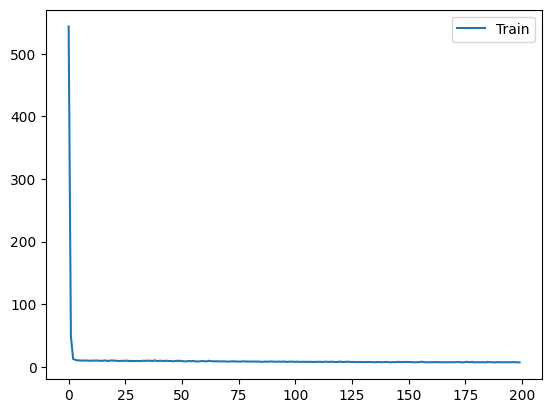

In [71]:
import matplotlib.pyplot as plt

plt.plot(range(epochs) , loss_plot , label='Train')
plt.legend()
plt.show()

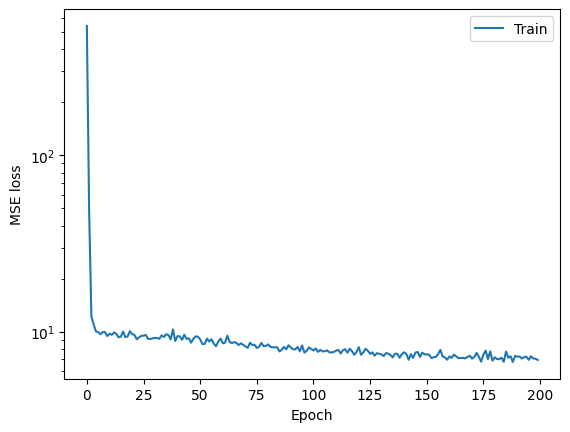

In [73]:
plt.plot(range(epochs), loss_plot, label='Train')
plt.yscale('log')            # option A: log scale
plt.xlabel('Epoch')
plt.ylabel('MSE loss')
plt.legend()
plt.show()

In [74]:
with torch.no_grad():
    pred = model(x_test.float())[:, 0]
    loss = loss_fn(pred, y_test)

    print(f'Test MSE: {loss.item():.4f}  |  MAE: {abs(pred - y_test).mean():.4f}')

Test MSE: 5.5979  |  MAE: 1.7947


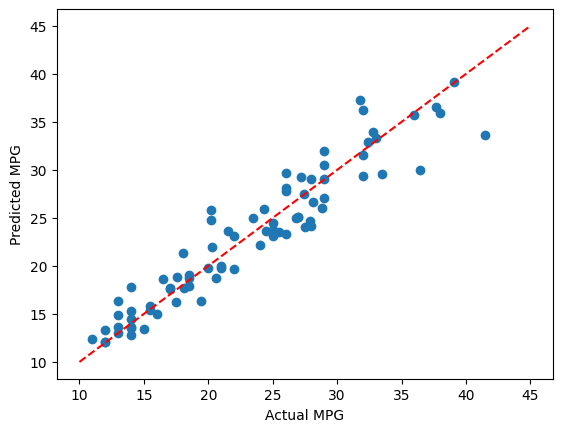

In [75]:
plt.scatter(y_test, pred)
plt.plot([10, 45], [10, 45], 'r--')   # perfect-prediction line
plt.xlabel('Actual MPG'); plt.ylabel('Predicted MPG')
plt.show()